In [ ]:
from google.colab import files
uploaded = files.upload()

Saving UP_Heatwave_RAW_data_clean (5).csv to UP_Heatwave_RAW_data_clean (5).csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
filename = next(iter(uploaded))

In [ ]:
df = pd.read_csv(filename)

print("DATASET LOADED SUCCESSFULLY")
print("\nFirst 5 rows of the dataset:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

DATASET LOADED SUCCESSFULLY

First 5 rows of the dataset:
         date  T2M_MAX  T2M_MIN      T2M     RH2M    QV2M   TSOIL1  \
0  1984-01-01  21.0984   7.3688  14.1904  51.0924  5.3304  13.8684   
1  1984-01-02  16.3244   9.3172  12.5356  78.1076  7.4600  13.7500   
2  1984-01-03  21.2220   9.3640  14.1240  75.3128  7.7220  14.4436   
3  1984-01-04  23.0212   8.1280  15.1280  60.8104  6.5568  14.3704   
4  1984-01-05  19.7172   9.1048  14.5516  75.8072  8.1020  14.2064   

   ALLSKY_SFC_SW_DWN  CLRSKY_SFC_SW_DWN  CLOUD_AMT  ...  GWETROOT   WS10M  \
0           2.110604           4.484732     79.820  ...    0.4780  2.3824   
1           1.192184           4.717732     99.900  ...    0.4780  2.3024   
2           2.139228           4.643500     64.564  ...    0.4880  2.2360   
3           3.977552           4.366952     25.184  ...    0.4944  1.7380   
4           4.024808           4.510568     50.788  ...    0.4944  2.0968   

     WD10M       PS  PRECTOTCORR       TS  EVLAND    city 

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if len(numeric_cols) < 2:
    raise ValueError("The dataset must contain at least two numerical columns.")

In [ ]:
x_col = numeric_cols[0]
y_col = numeric_cols[1]

In [ ]:
data = df[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()

x = data[x_col].astype(float).tolist()
y = data[y_col].astype(float).tolist()

print("\nSelected Variables:", x_col, "and", y_col)
print("Number of valid observations:", len(x))


Selected Variables: T2M_MAX and T2M_MIN
Number of valid observations: 1917500


In [ ]:
def correlation_coefficient(x, y):
    n = len(x)

    if n != len(y) or n < 2:
        raise ValueError("Both variables must have equal length and at least 2 values.")

    mean_x = sum(x) / n
    mean_y = sum(y) / n

    numerator = sum(
        (x[i] - mean_x) * (y[i] - mean_y)
        for i in range(n)
    )

    denominator_x = sum((value - mean_x) ** 2 for value in x)
    denominator_y = sum((value - mean_y) ** 2 for value in y)

    denominator = (denominator_x * denominator_y) ** 0.5

    if denominator == 0:
        return None

    return numerator / denominator

In [ ]:
r = correlation_coefficient(x, y)

print("\nCORRELATION COEFFICIENT RESULT")

if r is None:
    print("Correlation cannot be calculated because one variable is constant.")
else:
    print(f"Correlation coefficient (r) = {r:.4f}")

    if r > 0:
        print("Interpretation: Positive correlation")
    elif r < 0:
        print("Interpretation: Negative correlation")
    else:
        print("Interpretation: No linear correlation")


CORRELATION COEFFICIENT RESULT
Correlation coefficient (r) = 0.8109
Interpretation: Positive correlation


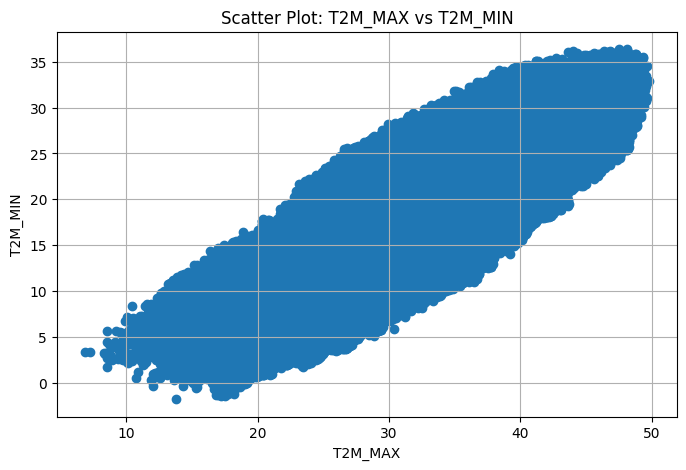

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y)
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title(f"Scatter Plot: {x_col} vs {y_col}")
plt.grid(True)
plt.show()


DEMONSTRATION OF THREE TYPES OF CORRELATION
Positive Correlation: r = 1.0000
Negative Correlation: r = -1.0000
No Linear Correlation: r = 0.5000


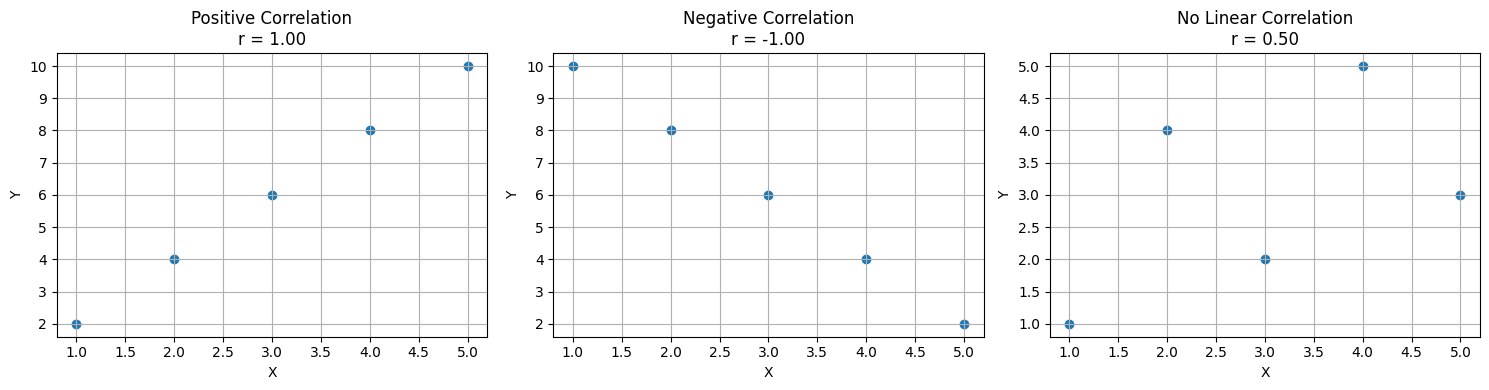

In [ ]:
examples = {
    "Positive Correlation": ([1, 2, 3, 4, 5], [2, 4, 6, 8, 10]),
    "Negative Correlation": ([1, 2, 3, 4, 5], [10, 8, 6, 4, 2]),
    "No Linear Correlation": ([1, 2, 3, 4, 5], [1, 4, 2, 5, 3])
}

print("\nDEMONSTRATION OF THREE TYPES OF CORRELATION")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (label, (a, b)) in zip(axes, examples.items()):
    result = correlation_coefficient(a, b)
    print(f"{label}: r = {result:.4f}")

    ax.scatter(a, b)
    ax.set_title(f"{label}\nr = {result:.2f}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(True)

plt.tight_layout()
plt.show()
